<a href="https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/exercicios/aula3-exercicio1-quanto-da-caixa-e-o-operario.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Aula 3, exercício 1: Quanto da caixa é o operário

Divida a área da máscara do operário pela área da caixa dele. Use a pessoa de maior máscara. O resultado fica entre 0 e 1: é a parte da caixa que é corpo de verdade.

O exercício é da aula [3. Medir a máscara](https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/notebooks/03-medir-a-mascara.ipynb), e este notebook roda sozinho. Use **Ambiente de execução → Executar tudo**: ele prepara os dados, deixa uma célula para você tentar e, no fim, mostra uma solução já conferida.

In [1]:
!pip install -q ultralytics

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mascaras_originais(resultado):
    """Máscaras no tamanho da foto, como array booleano (n, altura, largura).

    A rede responde numa grade menor que a imagem. Aqui a máscara é esticada
    de volta ao tamanho original, para a área bater com os pixels da foto.
    """
    import cv2
    import numpy as np

    altura, largura = resultado.orig_shape
    if resultado.masks is None or len(resultado.masks) == 0:
        return np.zeros((0, altura, largura), dtype=bool)
    saida = []
    for mascara in resultado.masks.data.cpu().numpy():
        mascara = cv2.resize(mascara, (largura, altura), interpolation=cv2.INTER_NEAREST)
        saida.append(mascara > 0.5)
    return np.stack(saida)


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

## Preparação

A preparação segmenta a foto dos operários na obra. Ficam prontos `resultado` e `mascaras`, no tamanho da foto.

operarios.jpg: 0.6 MB


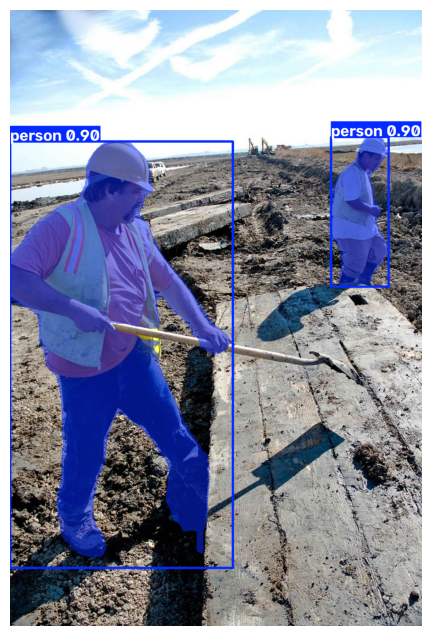

2 máscaras


In [3]:
import numpy as np
import cv2
from ultralytics import YOLO
import matplotlib.pyplot as plt

model = YOLO("yolov8n-seg.pt")
imagem = baixar("https://raw.githubusercontent.com/naubergois/curso-segmentacao-colab/main/midia/operarios.jpg", "operarios.jpg")
resultado = model(imagem, verbose=False)[0]
mascaras = mascaras_originais(resultado)

plt.figure(figsize=(6, 8))
plt.imshow(resultado.plot()[:, :, ::-1])
plt.axis("off")
plt.show()
print(len(mascaras), "máscaras")

In [4]:
# @title Correção automática (rode, não precisa ler)
import numpy as np

_cls = resultado.boxes.cls.int().tolist()
_xyxy = resultado.boxes.xyxy.tolist()


def _indices(nome):
    return [i for i, c in enumerate(_cls) if model.names[c] == nome]


def _i_pessoa():
    return max(_indices("person"), key=lambda i: int(mascaras[i].sum()))


def _razao_caixa(i):
    x1, y1, x2, y2 = _xyxy[i]
    return float(mascaras[i].sum()) / ((x2 - x1) * (y2 - y1))


def _centro(i):
    ys, xs = np.where(mascaras[i])
    return (int(round(xs.mean())), int(round(ys.mean())))


def _iou_caixa(i):
    caixa = np.zeros(mascaras.shape[1:], dtype=bool)
    x1, y1, x2, y2 = map(int, _xyxy[i])
    caixa[y1:y2, x1:x2] = True
    inter = np.logical_and(mascaras[i], caixa).sum()
    uniao = np.logical_or(mascaras[i], caixa).sum()
    return float(inter / uniao)


def _pares():
    n = len(mascaras)
    return sum(
        bool(np.any(mascaras[i] & mascaras[j]))
        for i in range(n) for j in range(i + 1, n)
    )


def _recorte():
    i = _i_pessoa()
    ys, xs = np.where(mascaras[i])
    return (int(ys.max() - ys.min() + 1), int(xs.max() - xs.min() + 1))


VERIFICAR = {
    1: lambda r: abs(float(r) - _razao_caixa(_i_pessoa())) < 1e-3,
    2: lambda r: abs(float(r) - float(mascaras[_i_pessoa()].mean()) * 100) < 0.1,
    3: lambda r: tuple(getattr(r, "shape", r)[:2]) == _recorte(),
    4: lambda r: all(abs(int(a) - b) <= 1 for a, b in zip(r, _centro(_i_pessoa()))),
    5: lambda r: abs(float(r) - _iou_caixa(_i_pessoa())) < 1e-3,
    6: lambda r: int(r) == _pares(),
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

## Sua vez

Divida a área da máscara do operário pela área da caixa dele. Use a pessoa de maior máscara. O resultado fica entre 0 e 1: é a parte da caixa que é corpo de verdade.

*Dica:* Área da caixa: (x2 - x1) * (y2 - y1), com os cantos em resultado.boxes.xyxy.

Troque o `None` pela sua resposta e rode a célula.

In [5]:
resposta = None

conferir(1, resposta)

Exercício 1: ainda sem resposta.


## Uma solução

Compare com o que você fez. Existem outros caminhos certos: o que vale é a `conferir` aprovar.

In [6]:
i = max(
    (k for k, c in enumerate(resultado.boxes.cls) if model.names[int(c)] == "person"),
    key=lambda k: int(mascaras[k].sum()),
)
x1, y1, x2, y2 = resultado.boxes.xyxy[i].tolist()
resposta = float(mascaras[i].sum()) / ((x2 - x1) * (y2 - y1))

conferir(1, resposta)

Exercício 1: ✅ certo!


## O que fica

Próximo: [Aula 3, exercício 2: Porcentagem da foto](https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/exercicios/aula3-exercicio2-porcentagem-da-foto.ipynb).